# Практическая работа 3. Самостоятельная работа (С1–С8)

Укажите свой номер варианта в `VARIANT`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ===== Параметры варианта 1 (строка 1 паспорта) =====
a, b, c = 1, -2, -3
x_left, x_right = -3, 3
N = 41
x_check = -1

data_center, data_scale = -2, 0.5

M = 600
sigma = 0.2
seed = 101
bins = 12

print(f"Вариант 1: P(x) = {a}x^2 + ({b})x + ({c})")

Вариант 1: P(x) = 1x^2 + (-2)x + (-3)


## С1. Параметризованная функция

In [3]:
def polynomial(x, a, b, c):
    """P(x) = a*x^2 + b*x + c."""
    return a*x**2 + b*x + c

print("P(x_check) =", polynomial(x_check, a, b, c))   # P(-1) = 0
print("P(2)       =", polynomial(2, a, b, c))         # P(2) = -3

P(x_check) = 0
P(2)       = -3


## С2. Дискретное представление функции

N = 41  h = 0.1499999999999999
y = [12.     10.8225  9.69    8.6025  7.56    6.5625  5.61    4.7025  3.84
  3.0225  2.25    1.5225  0.84    0.2025 -0.39   -0.9375 -1.44   -1.8975
 -2.31   -2.6775 -3.     -3.2775 -3.51   -3.6975 -3.84   -3.9375 -3.99
 -3.9975 -3.96   -3.8775 -3.75   -3.5775 -3.36   -3.0975 -2.79   -2.4375
 -2.04   -1.5975 -1.11   -0.5775  0.    ]


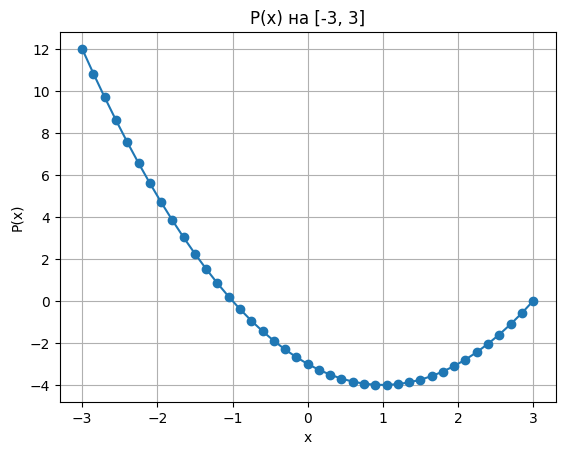

In [4]:
x = np.linspace(x_left, x_right, N)     # N точек от -3 до 3
y = polynomial(x, a, b, c)

print("N =", x.size, " h =", x[1] - x[0])
print("y =", y)

plt.plot(x, y, marker="o")
plt.xlabel("x"); plt.ylabel("P(x)"); plt.title("P(x) на [-3, 3]")
plt.grid(True)
plt.show()

## С3. Стандартное отклонение как собственная функция

In [5]:
def variance_manual(data):
    mu = np.mean(data)
    return np.mean((data - mu)**2)

def std_manual(data):
    return variance_manual(data)**0.5

offsets = np.array([-2, -1, -1, 0, 1, 2, 3], dtype=float)
data = data_center + data_scale * offsets

print("std manual =", std_manual(data), " std numpy =", np.std(data))

std manual = 0.8329931278350429  std numpy = 0.8329931278350429


## С4. Воспроизводимая нормальная случайная выборка

In [6]:
rng1 = np.random.default_rng(seed)
rng2 = np.random.default_rng(seed)
sample1 = rng1.normal(0.0, sigma, M)
sample2 = rng2.normal(0.0, sigma, M)

print("совпадают:", np.array_equal(sample1, sample2))
print("mean =", np.mean(sample1), " std =", np.std(sample1))

совпадают: True
mean = -0.007484098037789309  std = 0.2004605184104761


## С5. Зашумлённые данные и остаток

residual mean = -0.0016263883742926298  std = 0.20215407593547338  (sigma = 0.2 )


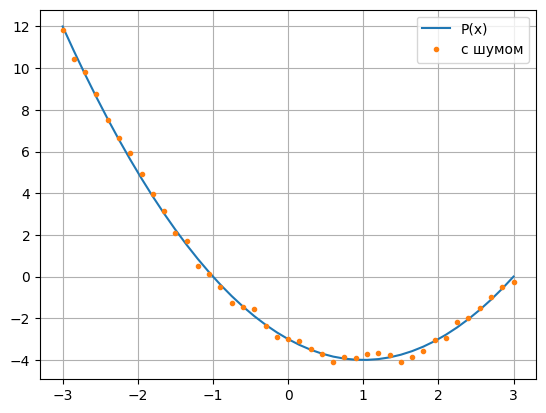

In [7]:
def add_normal_noise(y, sigma, seed):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0.0, sigma, size=y.shape)
    return y + noise

x = np.linspace(x_left, x_right, N)
y_clean = polynomial(x, a, b, c)
y_noisy = add_normal_noise(y_clean, sigma, seed)
r = y_noisy - y_clean                 # остаток

print("residual mean =", np.mean(r), " std =", np.std(r), " (sigma =", sigma, ")")

plt.plot(x, y_clean, label="P(x)")
plt.plot(x, y_noisy, ".", label="с шумом")
plt.legend(); plt.grid(True)
plt.show()

## С6. Квантили и межквартильный размах

In [8]:
q25, q50, q75 = np.quantile(r, [0.25, 0.50, 0.75])
iqr = q75 - q25
print("q25 =", q25, " median =", q50, " q75 =", q75)
print("IQR =", iqr)
print("mean =", np.mean(r))

q25 = -0.1580304999926021  median = 0.048771052148415484  q75 = 0.1415278041612149
IQR = 0.299558304153817
mean = -0.0016263883742926298


## С7. Гистограмма распределения

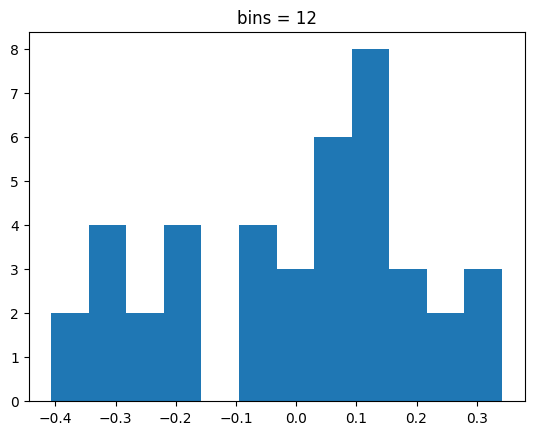

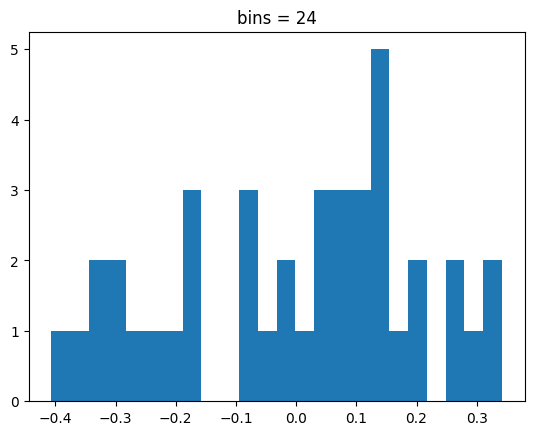

In [9]:
plt.hist(r, bins=bins); plt.title("bins = " + str(bins)); plt.show()
plt.hist(r, bins=2*bins); plt.title("bins = " + str(2*bins)); plt.show()

## С8. Функция статистического описания

In [10]:
def describe_data(data):
    q25, q50, q75 = np.quantile(data, [0.25, 0.50, 0.75])
    return np.mean(data), np.std(data), np.min(data), np.max(data), q25, q50, q75

mean_v, std_v, min_v, max_v, q25, q50, q75 = describe_data(r)
print(mean_v, std_v, min_v, max_v, q25, q50, q75)

-0.0016263883742926298 0.20215407593547338 -0.40692509636637375 0.34207885829552875 -0.1580304999926021 0.048771052148415484 0.1415278041612149
